In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import re
import os
import numpy as np
from lifelines import AalenJohansenFitter, KaplanMeierFitter
from Models.SyntheticData.simulate_data import simulate_competing_risks


# Data Check


In [2]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)



# 1. Synthetic Data
df_synthetic, true_beta_event1, true_beta_event2 = simulate_competing_risks(
    n_samples=15000, 
    seed=42,
    baseline_hazard_event1=0.01, 
    baseline_hazard_event2=0.05,
    censoring_rate=0.01
)

# 2. Real-World Datasets
df_PBC = pd.read_csv('./RealWorldData/pbc_competing_risks_processed.csv')
df_PBC2 = pd.read_csv('./RealWorldData/grouped_pbc.csv')
df_farhingham = pd.read_csv('./RealWorldData/framingham_competing_risks.csv')

In [3]:
def validate_competing_risks(df, time_col, event_col, dataset_name, primary_event=1, competing_event=2):
    """
    Validates a dataset for competing risks modeling by outputting event distributions
    and plotting the Aalen-Johansen CIF against the standard Kaplan-Meier estimate.
    """
    T = df[time_col]
    E = df[event_col]
    
    # 1. Event Distribution Table
    total_samples = len(df)
    censored = (E == 0).sum()
    primary = (E == primary_event).sum()
    competing = (E == competing_event).sum()
    
    print(f"--- Event Distribution: {dataset_name} ---")
    print(f"Total Samples: {total_samples}")
    print(f"Censored (0): {censored} ({censored/total_samples:.1%})")
    print(f"Primary Event ({primary_event}): {primary} ({primary/total_samples:.1%})")
    print(f"Competing Event ({competing_event}): {competing} ({competing/total_samples:.1%})\n")
    
    # 2. Initialize Fitters
    ajf_primary = AalenJohansenFitter(calculate_variance=True)
    ajf_competing = AalenJohansenFitter(calculate_variance=True)
    kmf = KaplanMeierFitter()
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Fit and plot CIF for Primary Event
    ajf_primary.fit(T, E, event_of_interest=primary_event)
    ajf_primary.plot(ax=ax, label=f"CIF: Primary Event", color="tab:blue", ci_show=True)
    
    # Fit and plot CIF for Competing Event
    ajf_competing.fit(T, E, event_of_interest=competing_event)
    ajf_competing.plot(ax=ax, label=f"CIF: Competing Event", color="tab:orange", ci_show=True)
    
    # Fit and plot KM for Primary Event (Treating competing as censored)
    # E == primary_event creates a boolean array where only the primary event is considered an "event"
    kmf.fit(T, event_observed=(E == primary_event))
    # 1 - KM gives the standard incidence probability which overestimates risk
    kmf_prob = 1 - kmf.survival_function_
    ax.plot(kmf_prob.index, kmf_prob.values, label="KM Estimate (Primary)", 
            color="black", linestyle="--")
    
    # Formatting
    ax.set_title(f"Competing Risks Validation: {dataset_name}", pad=15, fontweight='bold')
    ax.set_xlabel("Time")
    ax.set_ylabel("Cumulative Probability")
    ax.set_ylim([0, 0.6])
    ax.legend(loc="best")
    
    plt.tight_layout()
    plt.show()

--- Event Distribution: Synthetic Data (N=15000) ---
Total Samples: 15000
Censored (0): 2181 (14.5%)
Primary Event (1): 3626 (24.2%)
Competing Event (2): 9193 (61.3%)



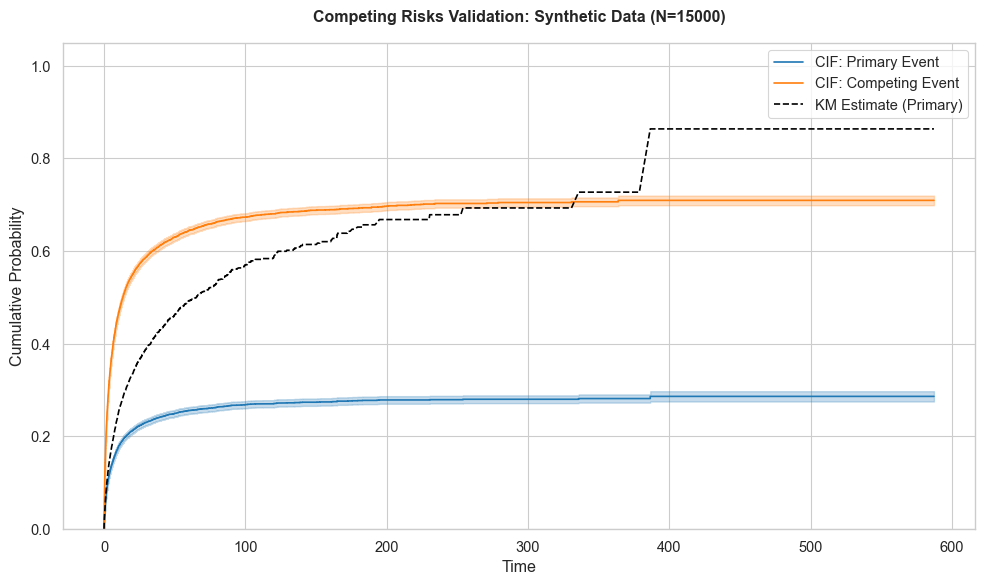

In [22]:
# Validate Synthetic Data
validate_competing_risks(df_synthetic, time_col='time', event_col='event', dataset_name='Synthetic Data (N=15000)')



--- Event Distribution: PBC Data ---
Total Samples: 1945
Censored (0): 1073 (55.2%)
Primary Event (1): 725 (37.3%)
Competing Event (2): 147 (7.6%)



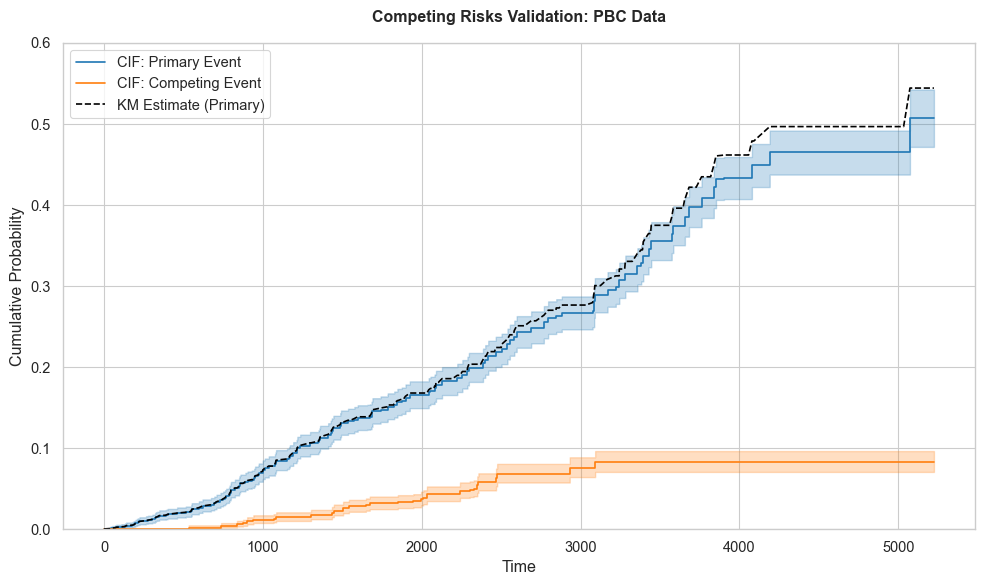

In [12]:
validate_competing_risks(df_PBC2, time_col='time', event_col='event', dataset_name='PBC Data')

--- Event Distribution: PBC Data ---
Total Samples: 1945
Censored (0): 1073 (55.2%)
Primary Event (1): 725 (37.3%)
Competing Event (2): 147 (7.6%)



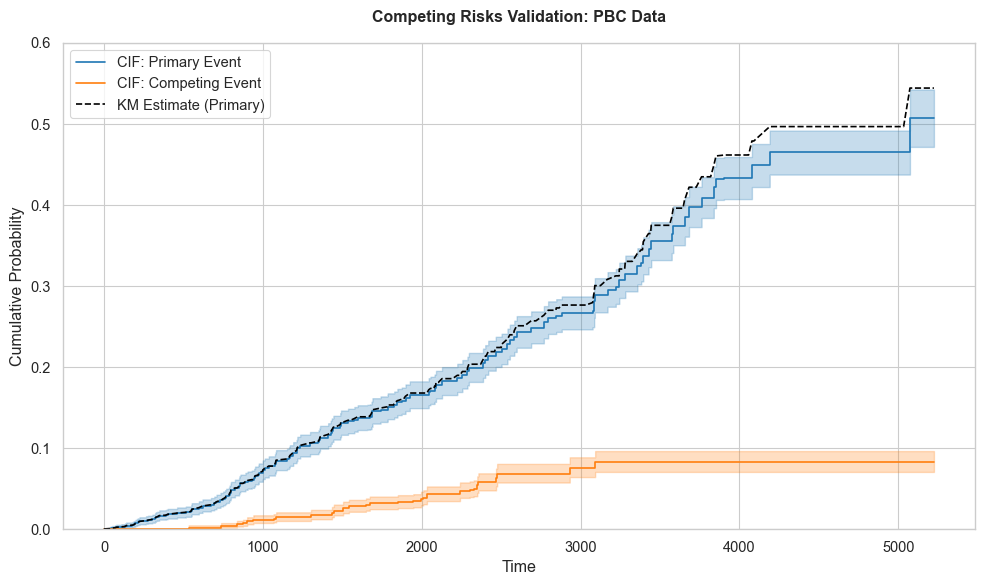

In [6]:
# Validate PBC Data
validate_competing_risks(df_PBC, time_col='time', event_col='event', dataset_name='PBC Data')



--- Event Distribution: Framingham Data ---
Total Samples: 4240
Censored (0): 3051 (72.0%)
Primary Event (1): 644 (15.2%)
Competing Event (2): 545 (12.9%)



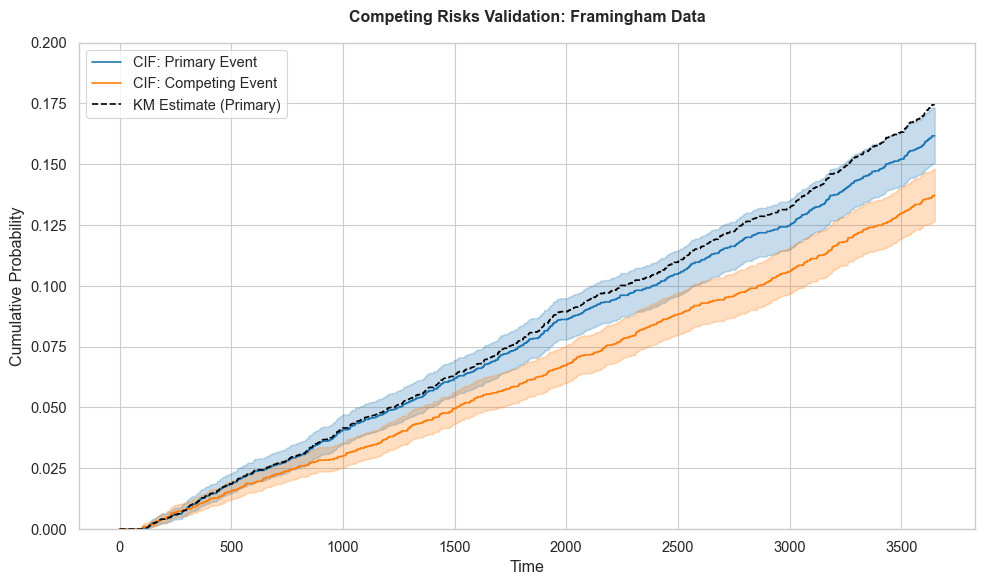

In [8]:
# Validate Framingham Data
validate_competing_risks(df_farhingham, time_col='time', event_col='event', dataset_name='Framingham Data')

# Synth

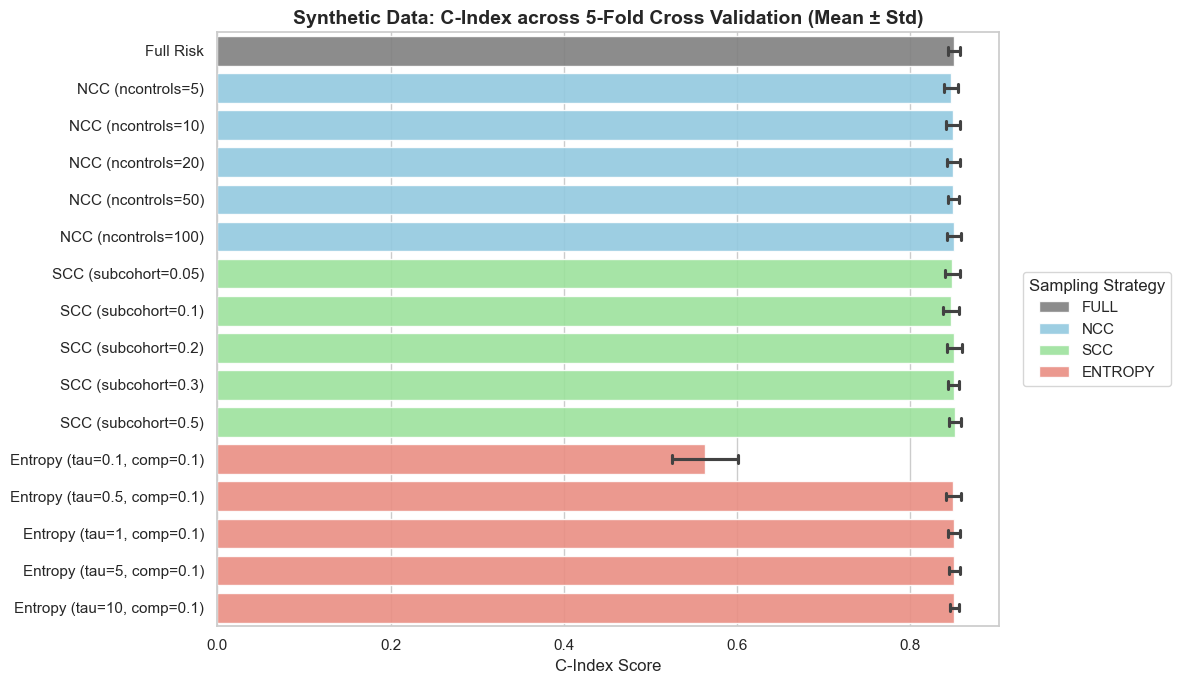

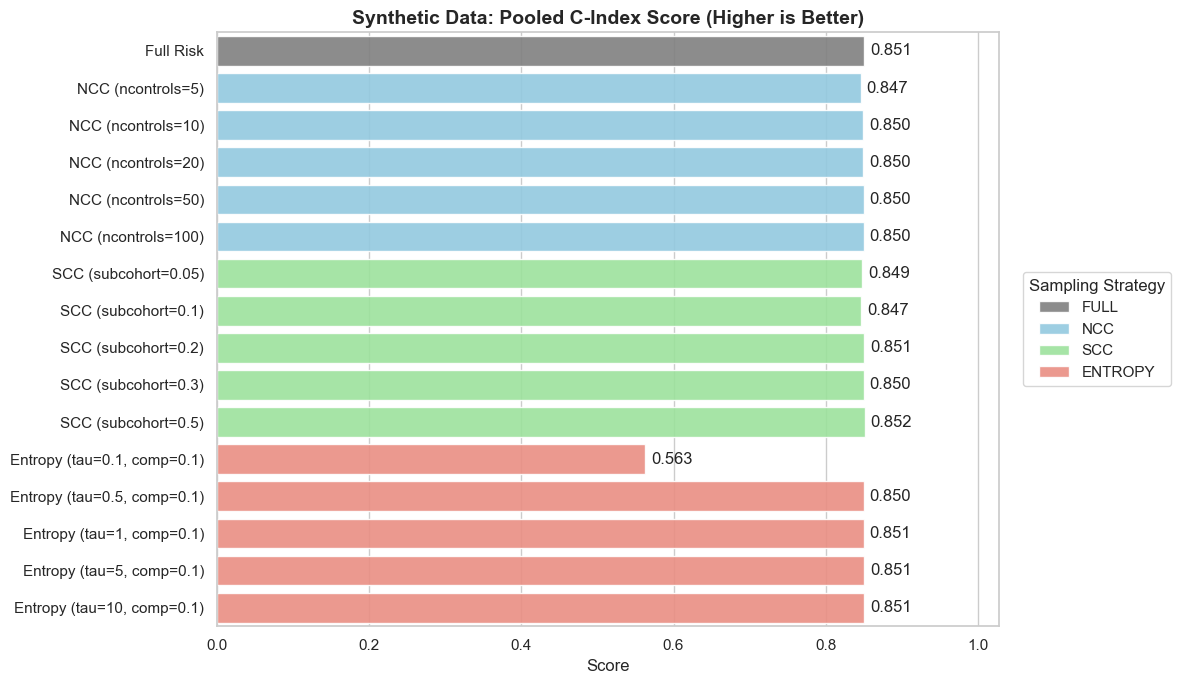

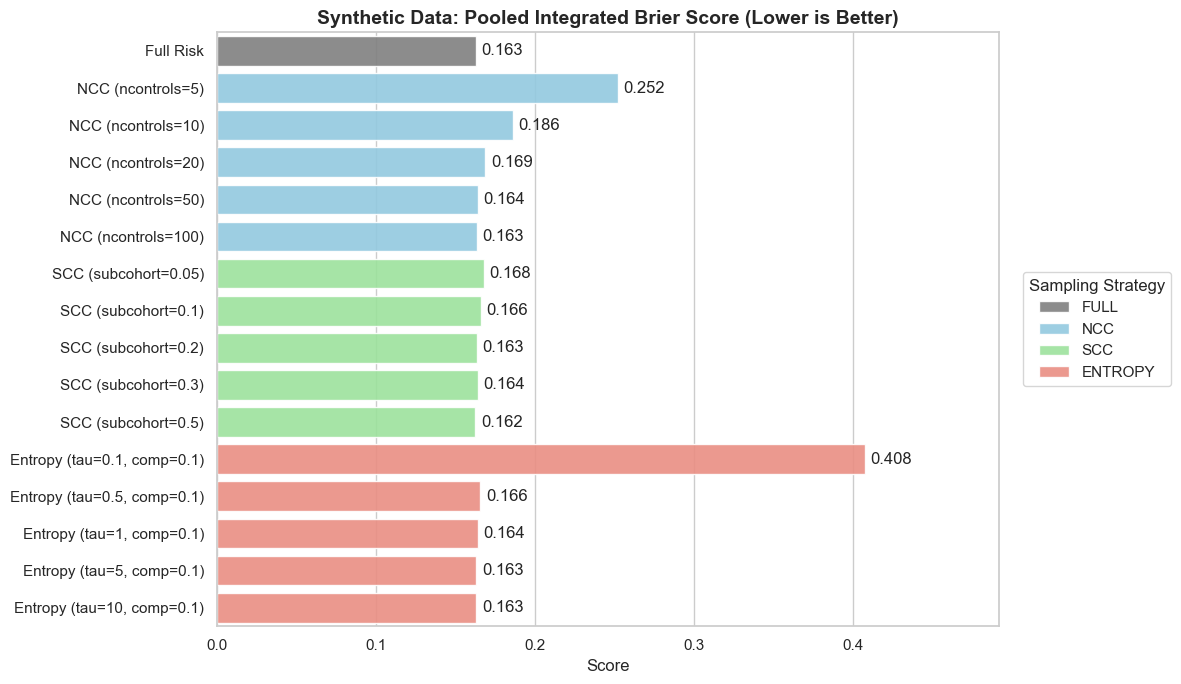

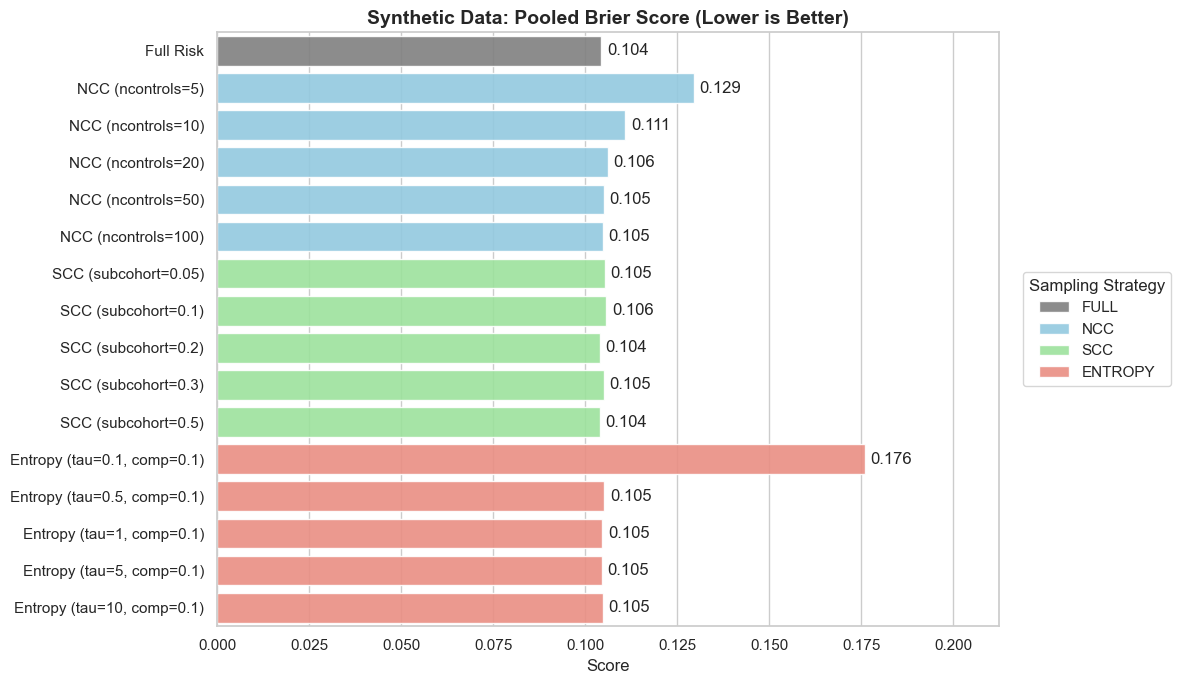

In [4]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL\Metrics",
    "NCC": r"Results\NCC\Metrics",
    "SCC": r"Results\SCC\Metrics",
    "ENTROPY": r"Results\ENTROPY\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    """
    Cleans the filename, generates a readable Y-axis label, and creates a 
    sort tuple so the chart is perfectly ordered: FULL -> NCC -> SCC -> ENTROPY.
    """
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
fold_cindex_data = []
pooled_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Parse View 1 Data (CV Folds)
        if filename.startswith("CIndex_scores_cause_1"):
            if 'Fold' in df.columns:
                df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            if 'CIndex_Score' in df_folds.columns:
                for val in df_folds['CIndex_Score']:
                    fold_cindex_data.append({
                        'Method': method, 'Label': label, 'SortKey': sort_key, 
                        'Metric': 'C-Index', 'Value': val
                    })
                    
        # Parse View 2 Data (Pooled Metrics)
        elif filename.startswith("pooled_oof_metrics"):
            if all(c in df.columns for c in ['pooled_c_index', 'pooled_ibs', 'pooled_brier']):
                pooled_data.append({
                    'Method': method, 'Label': label, 'SortKey': sort_key,
                    'Pooled C-Index': df['pooled_c_index'].iloc[0],
                    'Pooled IBS': df['pooled_ibs'].iloc[0],
                    'Pooled Brier': df['pooled_brier'].iloc[0]
                })

df_folds = pd.DataFrame(fold_cindex_data)
df_pooled = pd.DataFrame(pooled_data)

if df_folds.empty and df_pooled.empty:
    raise ValueError("No data extracted. Please verify your file paths relative to this Notebook.")

# Sort DataFrames by our computed Tuple so the Y-axis order is locked
df_folds = df_folds.sort_values(by='SortKey')
df_pooled = df_pooled.sort_values(by='SortKey')

# Unified aesthetic settings
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

# =========================================================
# VIEW 1: C-Index Mean with Std Error Bars (1 Image)
# =========================================================
if not df_folds.empty:
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=df_folds, 
        x='Value', 
        y='Label', 
        hue='Method',
        dodge=False,
        palette=method_colors,
        errorbar='sd',
        capsize=0.2,
        alpha=0.9
    )
    plt.title("Synthetic Data: C-Index across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
    plt.xlabel("C-Index Score")
    plt.ylabel("")
    plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout()
    plt.savefig("CIndex_mean_std_error.png", dpi=300, bbox_inches='tight')
    plt.show()

# =========================================================
# VIEW 2: Pooled OOF Metrics (3 Separate Images)
# =========================================================
if not df_pooled.empty:
    metrics_to_plot = {
        'Pooled C-Index': "Pooled C-Index Score (Higher is Better)",
        'Pooled IBS': "Pooled Integrated Brier Score (Lower is Better)",
        'Pooled Brier': "Pooled Brier Score (Lower is Better)"
    }
    
    for metric_col, title in metrics_to_plot.items():
        plt.figure(figsize=(12, 7))
        
        ax = sns.barplot(
            data=df_pooled, 
            x=metric_col, 
            y='Label', 
            hue='Method',
            dodge=False,
            palette=method_colors,
            alpha=0.9
        )
        
        # Add values to the bars formatted to 3 decimal places
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4)
            
        # Extend X-axis to prevent label cutoff
        xmin, xmax = ax.get_xlim()
        padding = (xmax - xmin) * 0.15
        ax.set_xlim(xmin, xmax + padding)
        
        plt.title(f"Synthetic Data: {title}", fontsize=14, weight='bold')
        plt.xlabel("Score")
        plt.ylabel("")
        plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
        plt.tight_layout()
        plt.savefig(f"{metric_col.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
        plt.show()

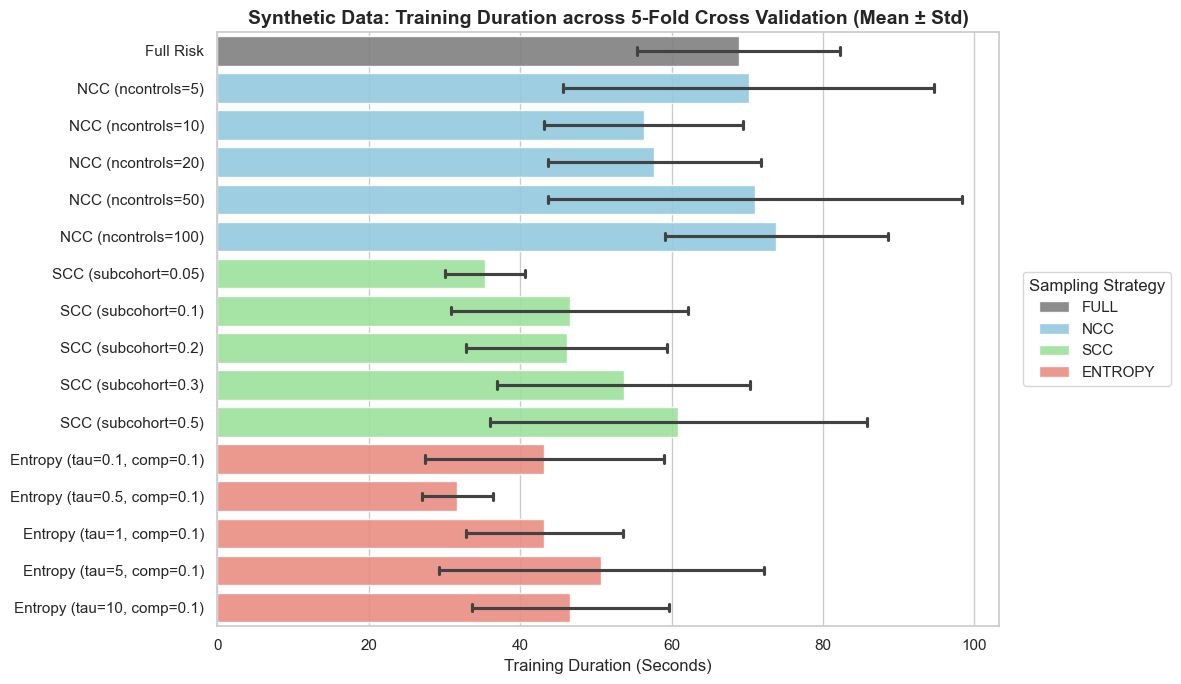

In [5]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL\Metrics",
    "NCC": r"Results\NCC\Metrics",
    "SCC": r"Results\SCC\Metrics",
    "ENTROPY": r"Results\ENTROPY\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
training_time_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        
        # Only parse Training Duration files
        if not filename.startswith("Training_Durations"):
            continue
            
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Filter out aggregate rows and extract individual fold times
        if 'Fold' in df.columns:
            df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            
        if 'Training_Duration' in df_folds.columns:
            for val in df_folds['Training_Duration']:
                training_time_data.append({
                    'Method': method, 
                    'Label': label, 
                    'SortKey': sort_key, 
                    'Duration (s)': float(val)
                })

df_time = pd.DataFrame(training_time_data)

if df_time.empty:
    raise ValueError("No training duration data extracted. Please verify your file paths.")

# Sort DataFrame by our computed Tuple so the Y-axis order matches previous charts
df_time = df_time.sort_values(by='SortKey')

# 4. Generate Visualization
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

plt.figure(figsize=(12, 7))
sns.barplot(
    data=df_time, 
    x='Duration (s)', 
    y='Label', 
    hue='Method',
    dodge=False,    # Keeps bars on a single axis without splitting
    palette=method_colors,
    errorbar='sd',  # Automatically calculates Mean and Standard Deviation from the 5 folds
    capsize=0.2,    # Adds the flat caps to the error bars
    alpha=0.9
)

plt.title("Synthetic Data: Training Duration across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
plt.xlabel("Training Duration (Seconds)")
plt.ylabel("")
plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.savefig("Training_Duration_mean_std_error.png", dpi=300, bbox_inches='tight')
plt.show()

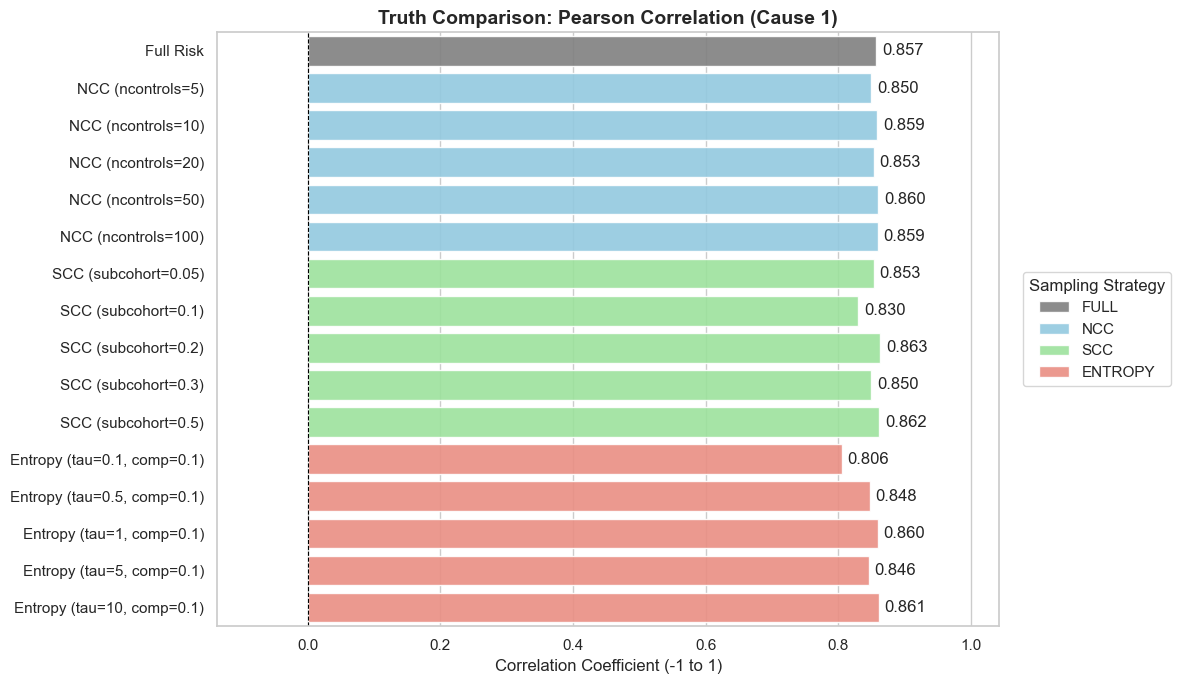

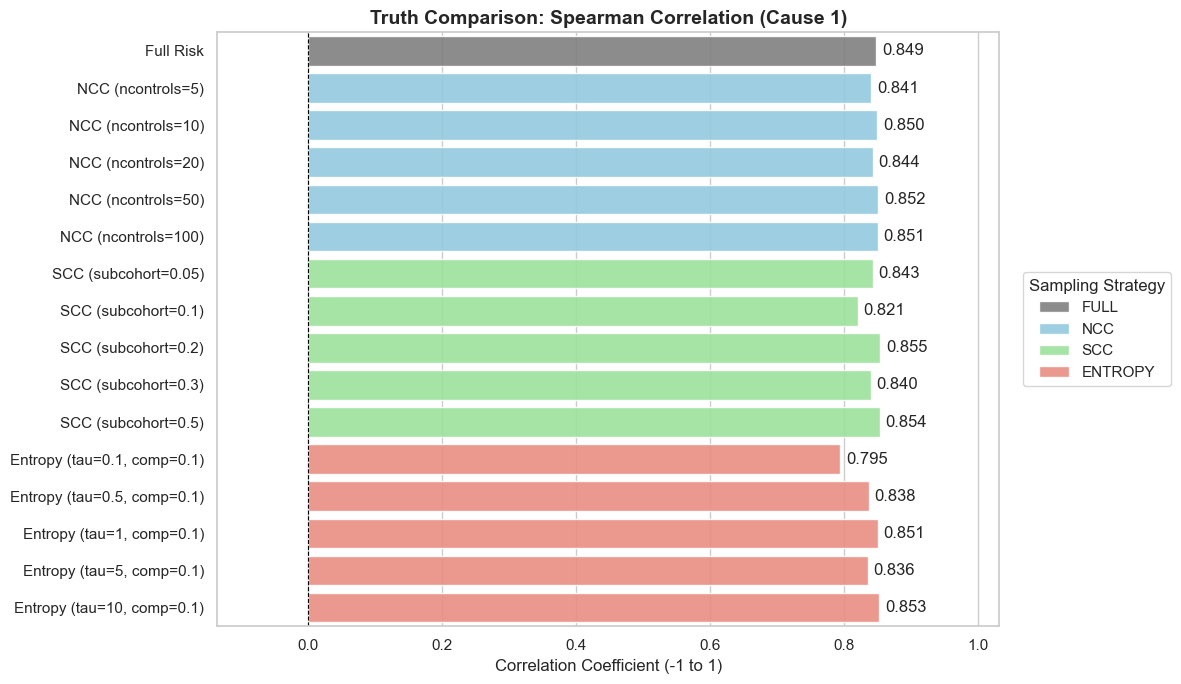

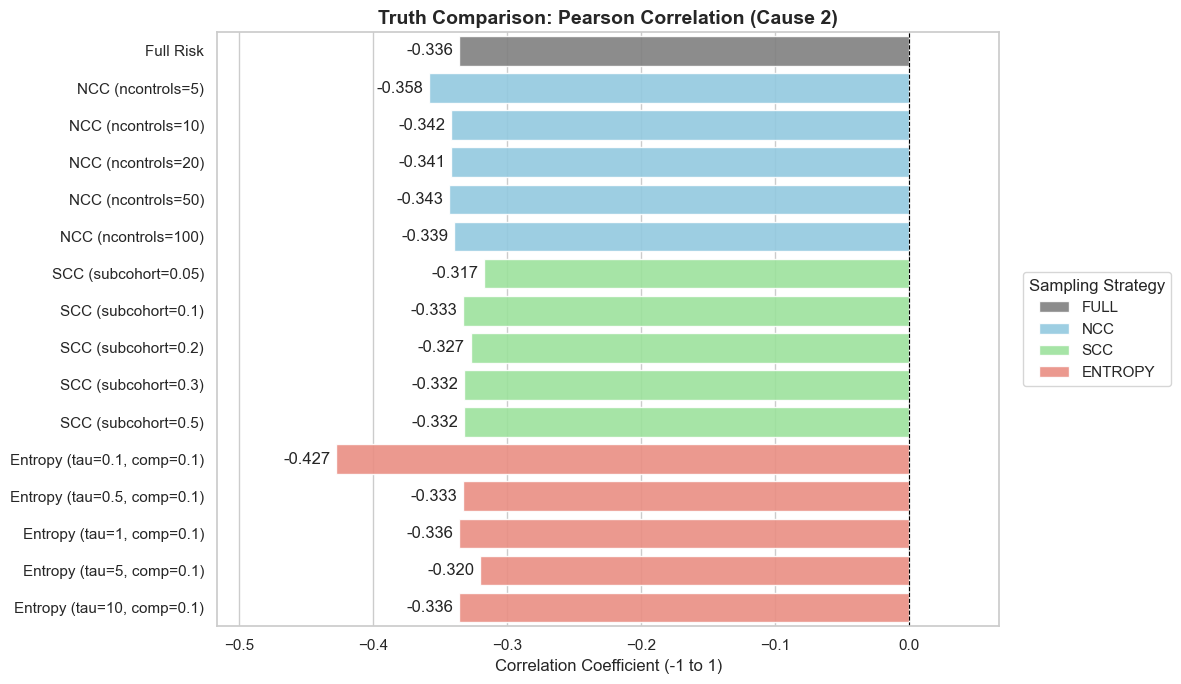

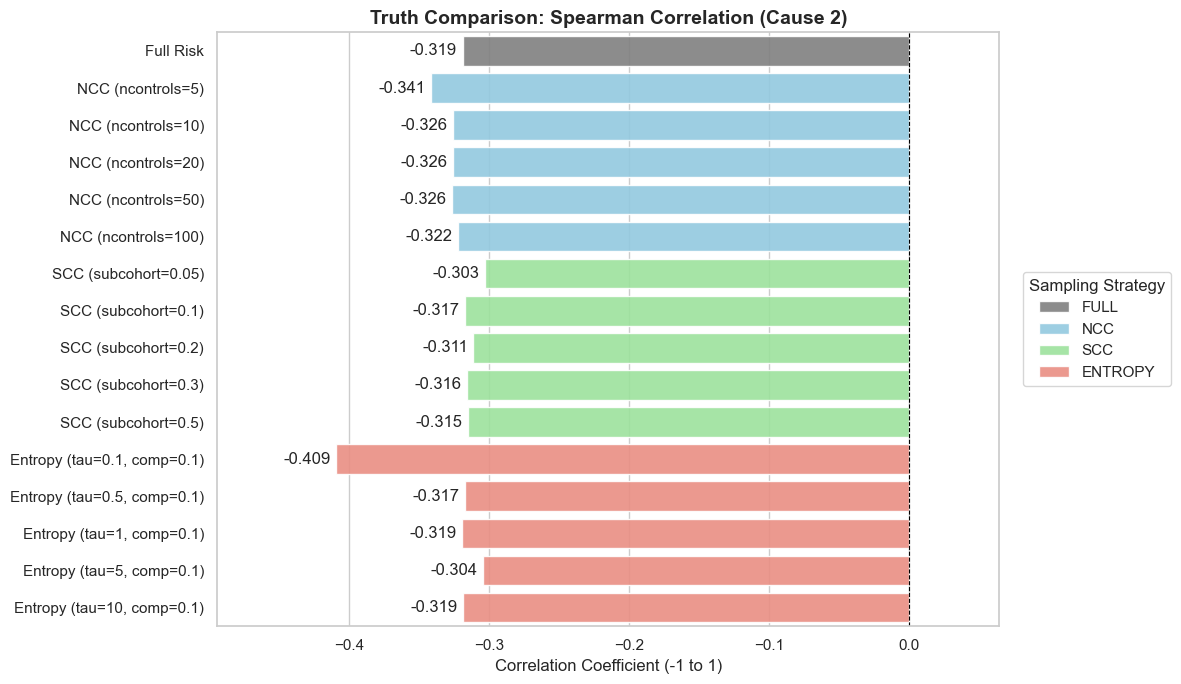

In [6]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL\Metrics",
    "NCC": r"Results\NCC\Metrics",
    "SCC": r"Results\SCC\Metrics",
    "ENTROPY": r"Results\ENTROPY\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
truth_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        
        if not filename.startswith("truth_comparison_metrics_cause_1"):
            continue
            
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        if not df.empty and all(col in df.columns for col in ['pearson_event1', 'spearman_event1', 'pearson_event2', 'spearman_event2']):
            truth_data.append({
                'Method': method, 
                'Label': label, 
                'SortKey': sort_key,
                'Pearson (Cause 1)': df['pearson_event1'].iloc[0],
                'Spearman (Cause 1)': df['spearman_event1'].iloc[0],
                'Pearson (Cause 2)': df['pearson_event2'].iloc[0],
                'Spearman (Cause 2)': df['spearman_event2'].iloc[0]
            })

df_truth = pd.DataFrame(truth_data)

if df_truth.empty:
    raise ValueError("No truth comparison data extracted. Please verify your file paths and contents.")

df_truth = df_truth.sort_values(by='SortKey')

# 4. Generate Visualizations
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

metrics_to_plot = {
    'Pearson (Cause 1)': "Truth Comparison: Pearson Correlation (Cause 1)",
    'Spearman (Cause 1)': "Truth Comparison: Spearman Correlation (Cause 1)",
    'Pearson (Cause 2)': "Truth Comparison: Pearson Correlation (Cause 2)",
    'Spearman (Cause 2)': "Truth Comparison: Spearman Correlation (Cause 2)"
}

for metric_col, title in metrics_to_plot.items():
    plt.figure(figsize=(12, 7))
    
    ax = sns.barplot(
        data=df_truth, 
        x=metric_col, 
        y='Label', 
        hue='Method',
        dodge=False,
        palette=method_colors,
        alpha=0.9
    )
    
    # Iterate through the bar containers and add labels formatted to 3 decimal places
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=4)
    
    # EXTEND X-AXIS LIMITS: Calculate current limits and add 15% padding to both sides
    xmin, xmax = ax.get_xlim()
    padding = (xmax - xmin) * 0.15
    ax.set_xlim(xmin - padding, xmax + padding)
    
    plt.title(title, fontsize=14, weight='bold')
    plt.xlabel("Correlation Coefficient (-1 to 1)") 
    plt.ylabel("")
    
    plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
    plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
    
    plt.tight_layout()
    plt.savefig(f"{metric_col.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    plt.show()

# PBC

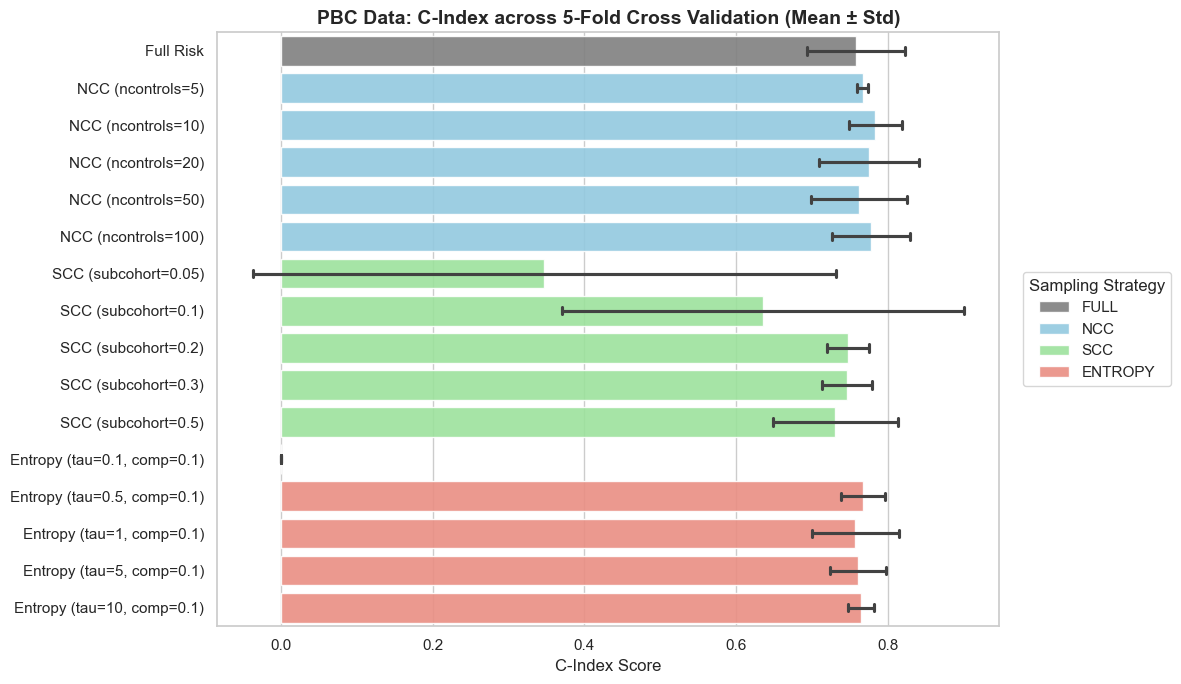

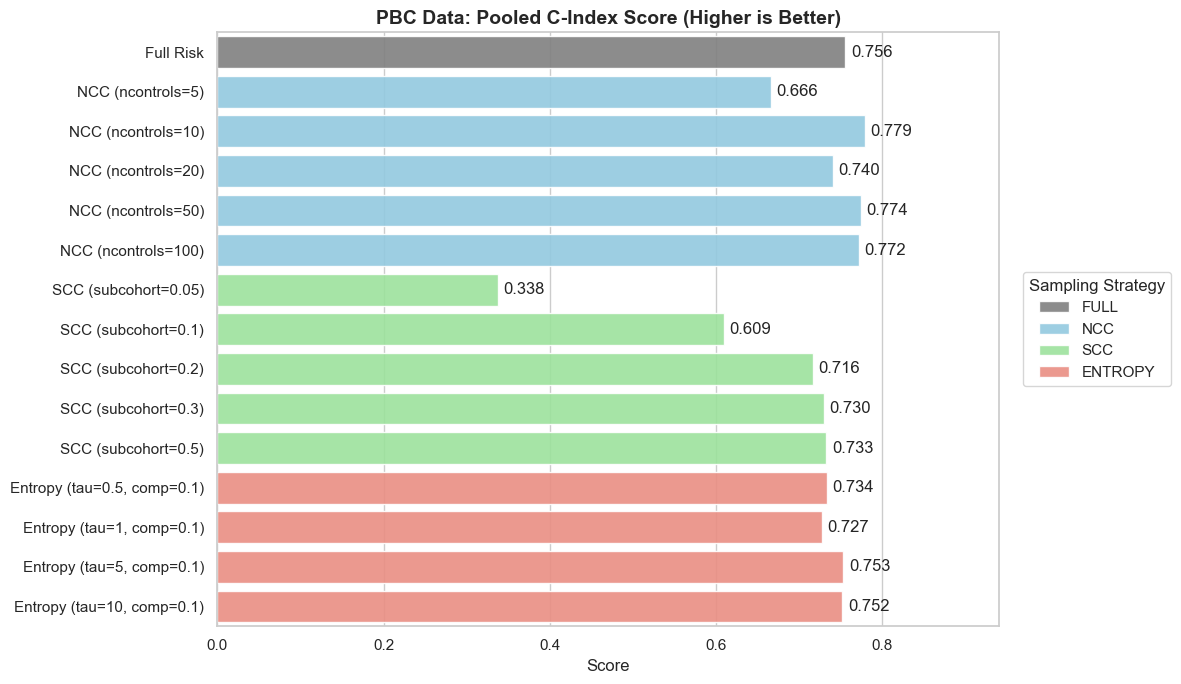

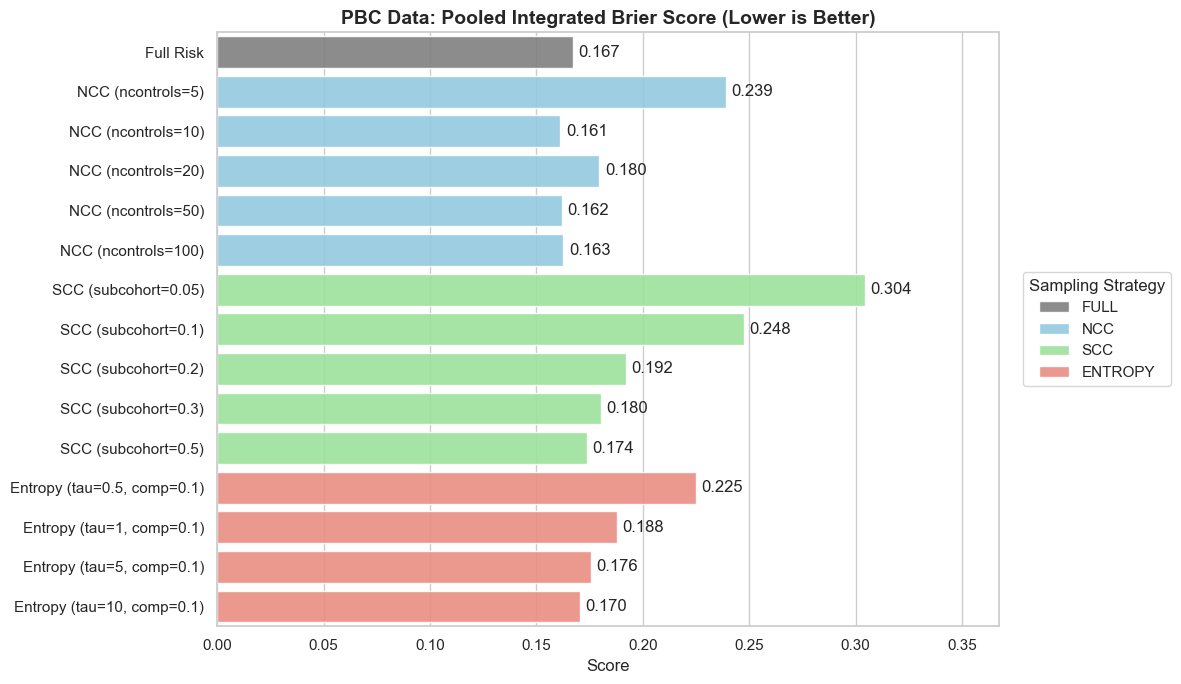

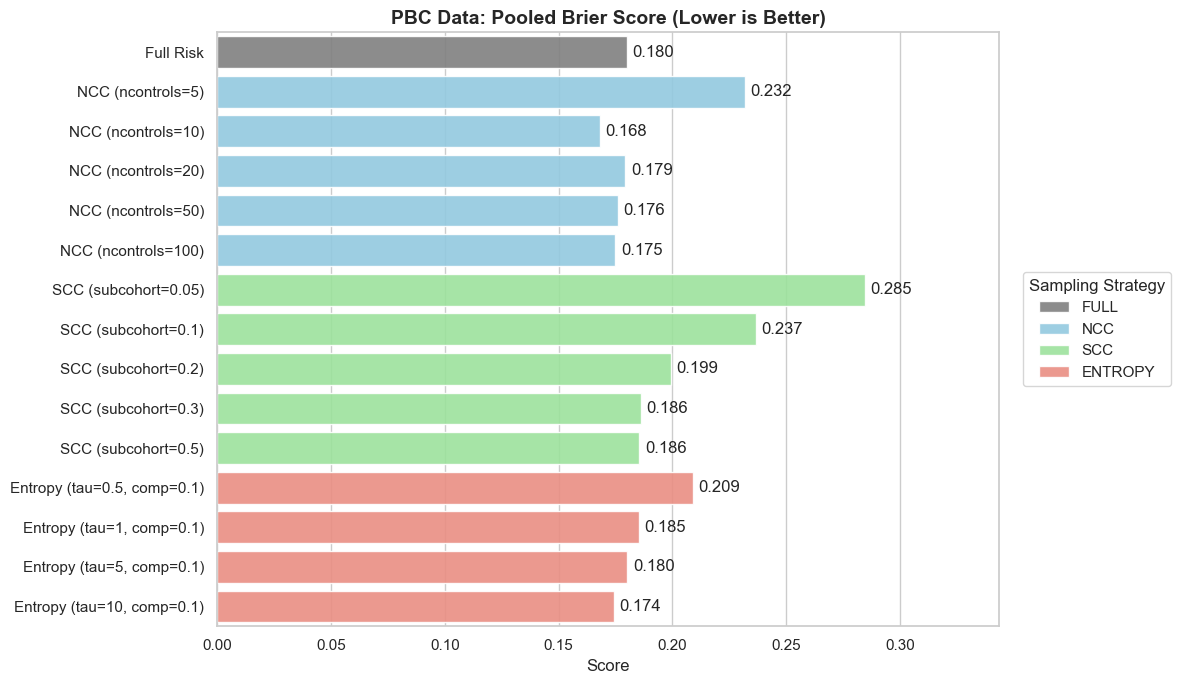

In [8]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL_PBC\Metrics",
    "NCC": r"Results\NCC_PBC\Metrics",
    "SCC": r"Results\SCC_PBC\Metrics",
    "ENTROPY": r"Results\ENTROPY_PBC\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    """
    Cleans the filename, generates a readable Y-axis label, and creates a 
    sort tuple so the chart is perfectly ordered: FULL -> NCC -> SCC -> ENTROPY.
    """
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
fold_cindex_data = []
pooled_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Parse View 1 Data (CV Folds)
        if filename.startswith("CIndex_scores_cause_1"):
            if 'Fold' in df.columns:
                df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            if 'CIndex_Score' in df_folds.columns:
                for val in df_folds['CIndex_Score']:
                    fold_cindex_data.append({
                        'Method': method, 'Label': label, 'SortKey': sort_key, 
                        'Metric': 'C-Index', 'Value': val
                    })
                    
        # Parse View 2 Data (Pooled Metrics)
        elif filename.startswith("pooled_oof_metrics"):
            if all(c in df.columns for c in ['pooled_c_index', 'pooled_ibs', 'pooled_brier']):
                pooled_data.append({
                    'Method': method, 'Label': label, 'SortKey': sort_key,
                    'Pooled C-Index': df['pooled_c_index'].iloc[0],
                    'Pooled IBS': df['pooled_ibs'].iloc[0],
                    'Pooled Brier': df['pooled_brier'].iloc[0]
                })

df_folds = pd.DataFrame(fold_cindex_data)
df_pooled = pd.DataFrame(pooled_data)

if df_folds.empty and df_pooled.empty:
    raise ValueError("No data extracted. Please verify your file paths relative to this Notebook.")

# Sort DataFrames by our computed Tuple so the Y-axis order is locked
df_folds = df_folds.sort_values(by='SortKey')
df_pooled = df_pooled.sort_values(by='SortKey')

# Unified aesthetic settings
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

# =========================================================
# VIEW 1: C-Index Mean with Std Error Bars (1 Image)
# =========================================================
if not df_folds.empty:
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=df_folds, 
        x='Value', 
        y='Label', 
        hue='Method',
        dodge=False,
        palette=method_colors,
        errorbar='sd',
        capsize=0.2,
        alpha=0.9
    )
    plt.title("PBC Data: C-Index across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
    plt.xlabel("C-Index Score")
    plt.ylabel("")
    plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout()
    plt.savefig("PBC_CIndex_mean_std_error.png", dpi=300, bbox_inches='tight')
    plt.show()

# =========================================================
# VIEW 2: Pooled OOF Metrics (3 Separate Images)
# =========================================================
if not df_pooled.empty:
    metrics_to_plot = {
        'Pooled C-Index': "Pooled C-Index Score (Higher is Better)",
        'Pooled IBS': "Pooled Integrated Brier Score (Lower is Better)",
        'Pooled Brier': "Pooled Brier Score (Lower is Better)"
    }
    
    for metric_col, title in metrics_to_plot.items():
        plt.figure(figsize=(12, 7))
        
        ax = sns.barplot(
            data=df_pooled, 
            x=metric_col, 
            y='Label', 
            hue='Method',
            dodge=False,
            palette=method_colors,
            alpha=0.9
        )
        
        # Add values to the bars formatted to 3 decimal places
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4)
            
        # Extend X-axis to prevent label cutoff
        xmin, xmax = ax.get_xlim()
        padding = (xmax - xmin) * 0.15
        ax.set_xlim(xmin, xmax + padding)
        
        plt.title(f"PBC Data: {title}", fontsize=14, weight='bold')
        plt.xlabel("Score")
        plt.ylabel("")
        plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
        plt.tight_layout()
        plt.savefig(f"{metric_col.replace(' ', '_')}_PBC.png", dpi=300, bbox_inches='tight')
        plt.show()

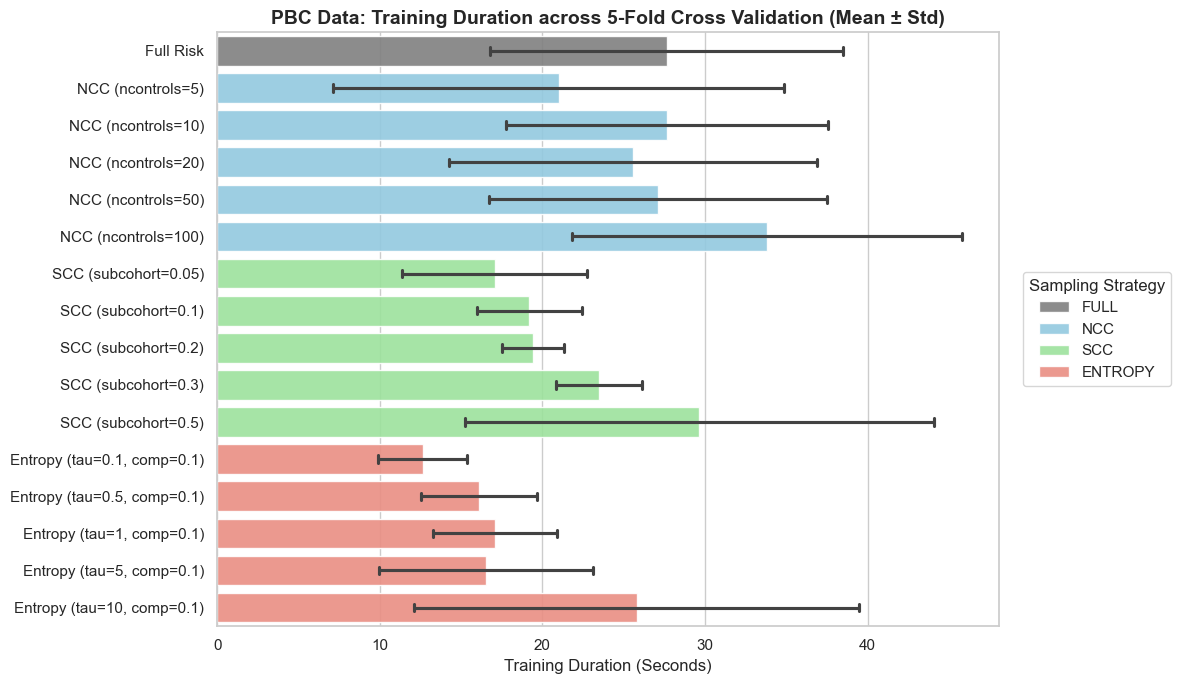

In [9]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL_PBC\Metrics",
    "NCC": r"Results\NCC_PBC\Metrics",
    "SCC": r"Results\SCC_PBC\Metrics",
    "ENTROPY": r"Results\ENTROPY_PBC\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
training_time_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        
        # Only parse Training Duration files
        if not filename.startswith("Training_Durations"):
            continue
            
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Filter out aggregate rows and extract individual fold times
        if 'Fold' in df.columns:
            df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            
        if 'Training_Duration' in df_folds.columns:
            for val in df_folds['Training_Duration']:
                training_time_data.append({
                    'Method': method, 
                    'Label': label, 
                    'SortKey': sort_key, 
                    'Duration (s)': float(val)
                })

df_time = pd.DataFrame(training_time_data)

if df_time.empty:
    raise ValueError("No training duration data extracted. Please verify your file paths.")

# Sort DataFrame by our computed Tuple so the Y-axis order matches previous charts
df_time = df_time.sort_values(by='SortKey')

# 4. Generate Visualization
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

plt.figure(figsize=(12, 7))
sns.barplot(
    data=df_time, 
    x='Duration (s)', 
    y='Label', 
    hue='Method',
    dodge=False,    # Keeps bars on a single axis without splitting
    palette=method_colors,
    errorbar='sd',  # Automatically calculates Mean and Standard Deviation from the 5 folds
    capsize=0.2,    # Adds the flat caps to the error bars
    alpha=0.9
)

plt.title("PBC Data: Training Duration across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
plt.xlabel("Training Duration (Seconds)")
plt.ylabel("")
plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.savefig("Training_Duration_mean_std_error_PBC.png", dpi=300, bbox_inches='tight')
plt.show()

# FH

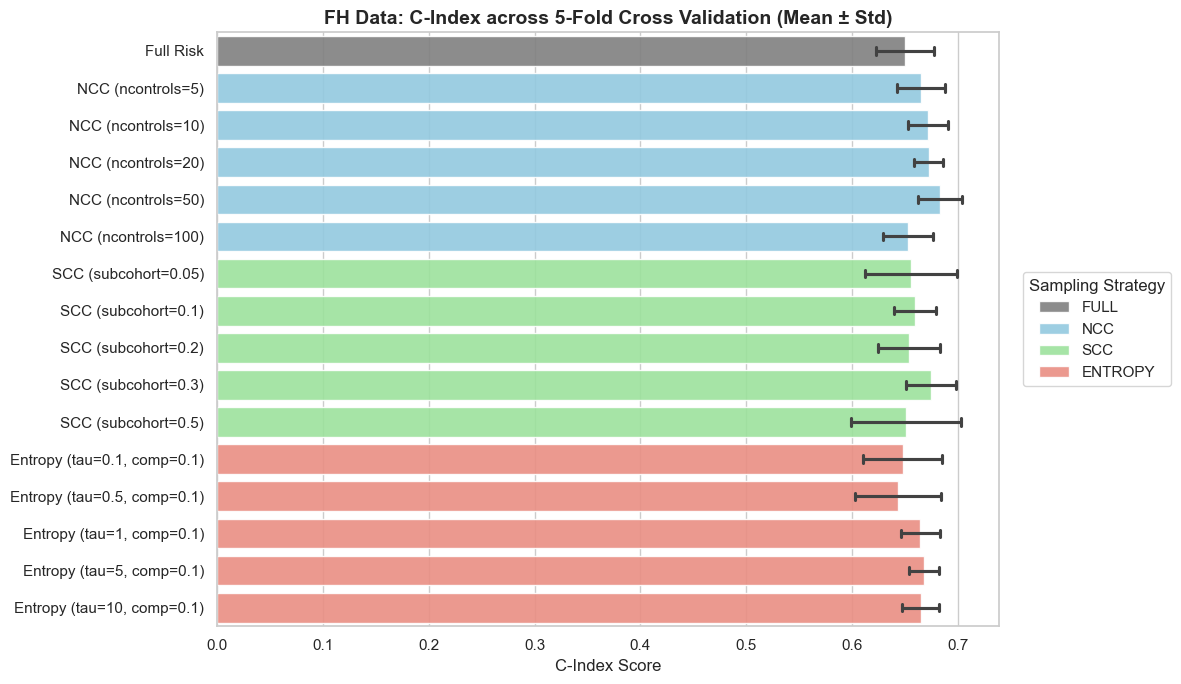

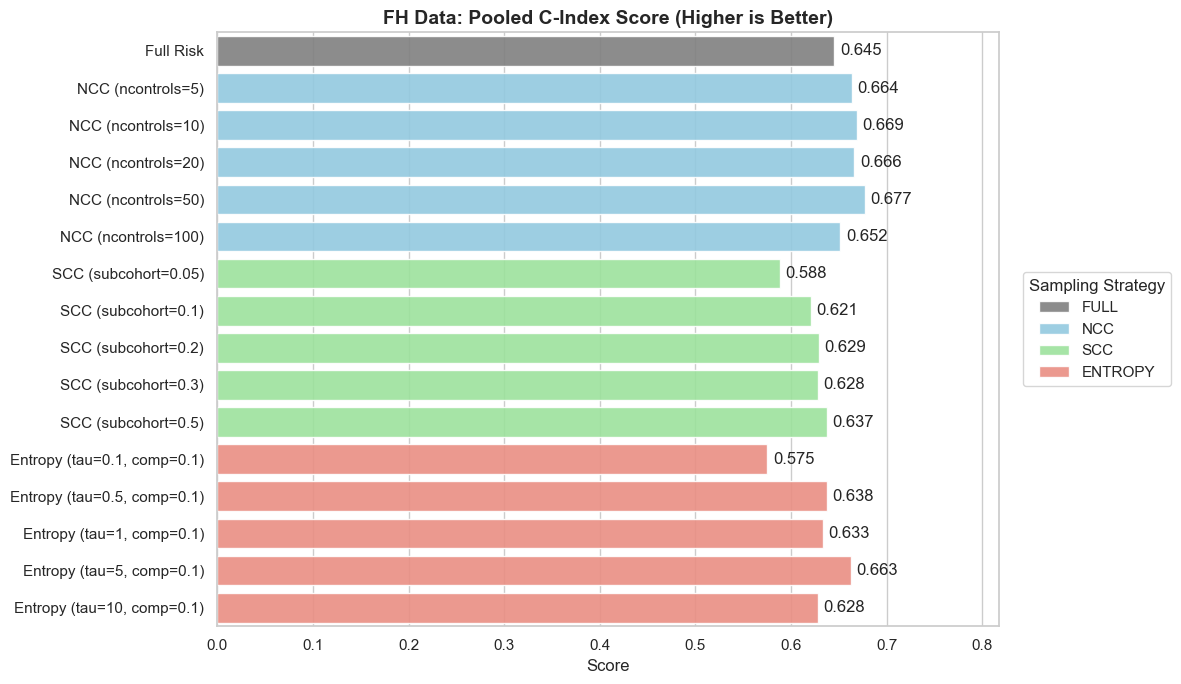

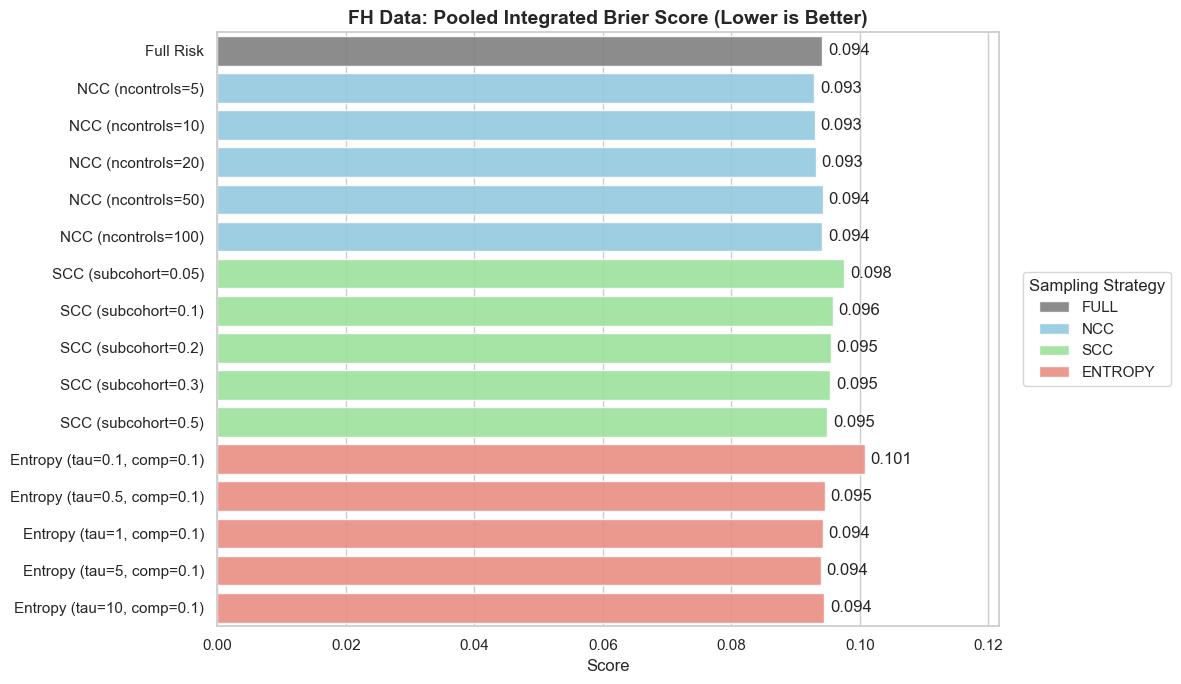

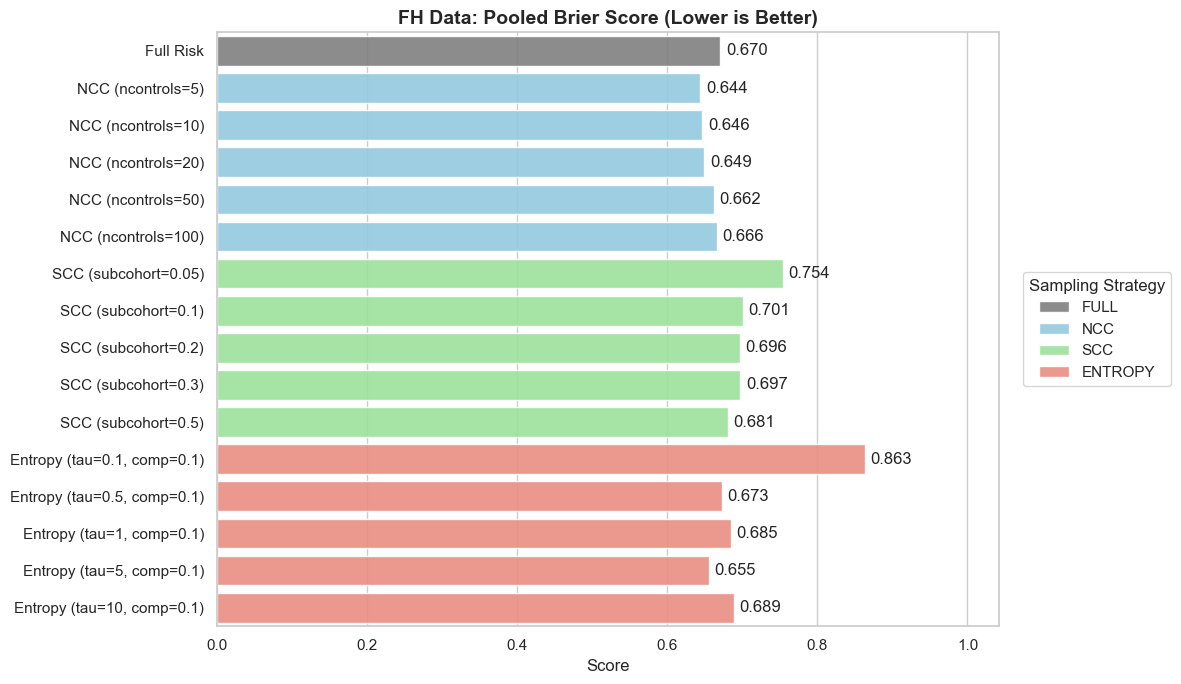

In [43]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL_FH\Metrics",
    "NCC": r"Results\NCC_FH\Metrics",
    "SCC": r"Results\SCC_FH\Metrics",
    "ENTROPY": r"Results\ENTROPY_FH\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    """
    Cleans the filename, generates a readable Y-axis label, and creates a 
    sort tuple so the chart is perfectly ordered: FULL -> NCC -> SCC -> ENTROPY.
    """
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
fold_cindex_data = []
pooled_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Parse View 1 Data (CV Folds)
        if filename.startswith("CIndex_scores_cause_1"):
            if 'Fold' in df.columns:
                df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            if 'CIndex_Score' in df_folds.columns:
                for val in df_folds['CIndex_Score']:
                    fold_cindex_data.append({
                        'Method': method, 'Label': label, 'SortKey': sort_key, 
                        'Metric': 'C-Index', 'Value': val
                    })
                    
        # Parse View 2 Data (Pooled Metrics)
        elif filename.startswith("pooled_oof_metrics"):
            if all(c in df.columns for c in ['pooled_c_index', 'pooled_ibs', 'pooled_brier']):
                pooled_data.append({
                    'Method': method, 'Label': label, 'SortKey': sort_key,
                    'Pooled C-Index': df['pooled_c_index'].iloc[0],
                    'Pooled IBS': df['pooled_ibs'].iloc[0],
                    'Pooled Brier': df['pooled_brier'].iloc[0]
                })

df_folds = pd.DataFrame(fold_cindex_data)
df_pooled = pd.DataFrame(pooled_data)

if df_folds.empty and df_pooled.empty:
    raise ValueError("No data extracted. Please verify your file paths relative to this Notebook.")

# Sort DataFrames by our computed Tuple so the Y-axis order is locked
df_folds = df_folds.sort_values(by='SortKey')
df_pooled = df_pooled.sort_values(by='SortKey')

# Unified aesthetic settings
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

# =========================================================
# VIEW 1: C-Index Mean with Std Error Bars (1 Image)
# =========================================================
if not df_folds.empty:
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=df_folds, 
        x='Value', 
        y='Label', 
        hue='Method',
        dodge=False,
        palette=method_colors,
        errorbar='sd',
        capsize=0.2,
        alpha=0.9
    )
    plt.title("FH Data: C-Index across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
    plt.xlabel("C-Index Score")
    plt.ylabel("")
    plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout()
    plt.savefig("FH_CIndex_mean_std_error.png", dpi=300, bbox_inches='tight')
    plt.show()

# =========================================================
# VIEW 2: Pooled OOF Metrics (3 Separate Images)
# =========================================================
if not df_pooled.empty:
    metrics_to_plot = {
        'Pooled C-Index': "Pooled C-Index Score (Higher is Better)",
        'Pooled IBS': "Pooled Integrated Brier Score (Lower is Better)",
        'Pooled Brier': "Pooled Brier Score (Lower is Better)"
    }
    
    for metric_col, title in metrics_to_plot.items():
        plt.figure(figsize=(12, 7))
        
        ax = sns.barplot(
            data=df_pooled, 
            x=metric_col, 
            y='Label', 
            hue='Method',
            dodge=False,
            palette=method_colors,
            alpha=0.9
        )
        
        # Add values to the bars formatted to 3 decimal places
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4)
            
        # Extend X-axis to prevent label cutoff
        xmin, xmax = ax.get_xlim()
        padding = (xmax - xmin) * 0.15
        ax.set_xlim(xmin, xmax + padding)
        
        plt.title(f"FH Data: {title}", fontsize=14, weight='bold')
        plt.xlabel("Score")
        plt.ylabel("")
        plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
        plt.tight_layout()
        plt.savefig(f"{metric_col.replace(' ', '_')}_FH.png", dpi=300, bbox_inches='tight')
        plt.show()

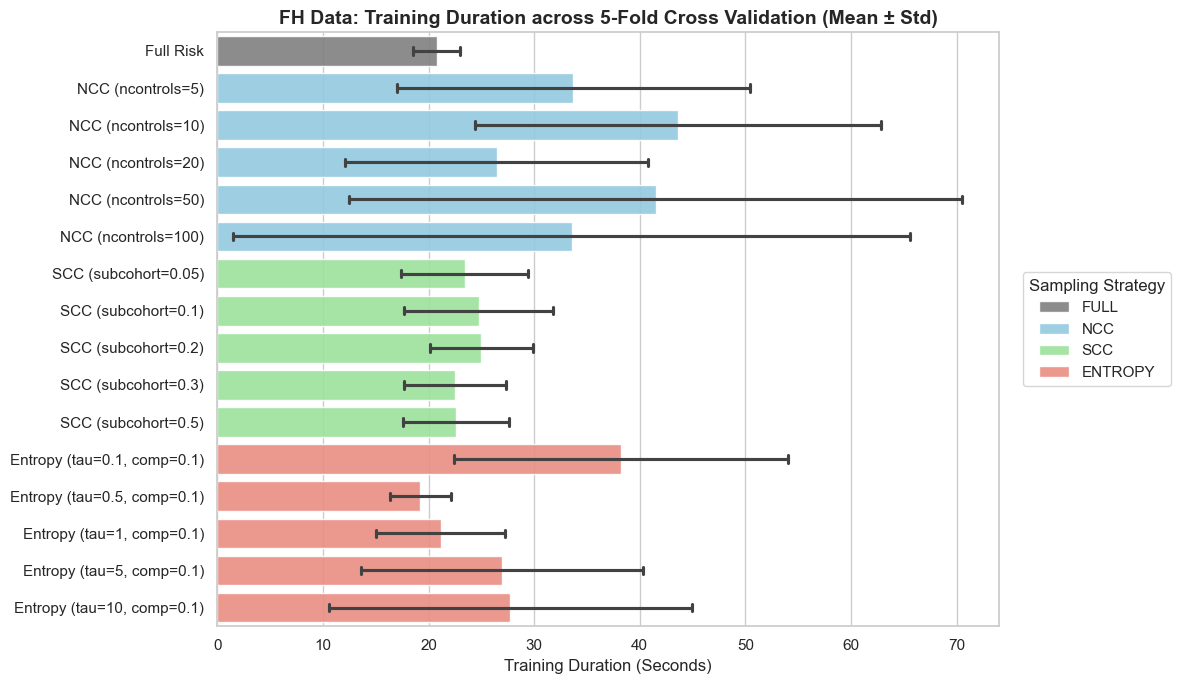

In [44]:
import os
import glob
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the base directories for the sampling methods
base_paths = {
    "FULL": r"Results\FULL_FH\Metrics",
    "NCC": r"Results\NCC_FH\Metrics",
    "SCC": r"Results\SCC_FH\Metrics",
    "ENTROPY": r"Results\ENTROPY_FH\Metrics"
}

# 2. Parsing Function to format labels and dictate the sorting order
def get_label_and_sort_key(method, fname):
    fname_clean = fname.replace(".csv", "")
    
    if method == "FULL":
        return "Full Risk", (0, 0, 0)
        
    elif method == "NCC":
        m = re.search(r"ncontrols_([0-9.]+)", fname_clean)
        nc = float(m.group(1)) if m else 0
        return f"NCC (ncontrols={int(nc) if nc.is_integer() else nc})", (1, nc, 0)
        
    elif method == "SCC":
        m = re.search(r"subcohort_([0-9.]+)", fname_clean)
        sc = float(m.group(1)) if m else 0
        return f"SCC (subcohort={sc})", (2, sc, 0)
        
    elif method == "ENTROPY":
        m = re.search(r"tau_([0-9.]+)_compression_([0-9.]+)", fname_clean)
        if m:
            tau, comp = float(m.group(1)), float(m.group(2))
            tau_str = f"{int(tau)}" if tau.is_integer() else f"{tau}"
            return f"Entropy (tau={tau_str}, comp={comp})", (3, tau, comp)
            
    return fname_clean, (4, 0, 0)

# 3. Data Extraction and Aggregation
training_time_data = []

for method, path in base_paths.items():
    if not os.path.exists(path):
        print(f"Directory not found (Skipping): {path}")
        continue
        
    for file_path in glob.glob(os.path.join(path, "*.csv")):
        filename = os.path.basename(file_path)
        
        # Only parse Training Duration files
        if not filename.startswith("Training_Durations"):
            continue
            
        label, sort_key = get_label_and_sort_key(method, filename)
        
        try:
            df = pd.read_csv(file_path)
        except Exception:
            continue
            
        # Filter out aggregate rows and extract individual fold times
        if 'Fold' in df.columns:
            df_folds = df[~df['Fold'].isin(['Mean', 'Std'])]
            
        if 'Training_Duration' in df_folds.columns:
            for val in df_folds['Training_Duration']:
                training_time_data.append({
                    'Method': method, 
                    'Label': label, 
                    'SortKey': sort_key, 
                    'Duration (s)': float(val)
                })

df_time = pd.DataFrame(training_time_data)

if df_time.empty:
    raise ValueError("No training duration data extracted. Please verify your file paths.")

# Sort DataFrame by our computed Tuple so the Y-axis order matches previous charts
df_time = df_time.sort_values(by='SortKey')

# 4. Generate Visualization
sns.set_theme(style="whitegrid", palette="muted")
method_colors = {"FULL": "grey", "NCC": "skyblue", "SCC": "lightgreen", "ENTROPY": "salmon"}

plt.figure(figsize=(12, 7))
sns.barplot(
    data=df_time, 
    x='Duration (s)', 
    y='Label', 
    hue='Method',
    dodge=False,    # Keeps bars on a single axis without splitting
    palette=method_colors,
    errorbar='sd',  # Automatically calculates Mean and Standard Deviation from the 5 folds
    capsize=0.2,    # Adds the flat caps to the error bars
    alpha=0.9
)

plt.title("FH Data: Training Duration across 5-Fold Cross Validation (Mean ± Std)", fontsize=14, weight='bold')
plt.xlabel("Training Duration (Seconds)")
plt.ylabel("")
plt.legend(title="Sampling Strategy", loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.savefig("Training_Duration_mean_std_error_FH.png", dpi=300, bbox_inches='tight')
plt.show()